#### RandomUnderSampler
With a Regression Target

Imports

In [ ]:
# RandomUnderSampler is imported from imblearn (imbalanced-learn)
# Load the cleaned laptop price dataset (target = Price, a regression target)
# pip install imblearn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.under_sampling import RandomUnderSampler, ClusterCentroids
import warnings

warnings.filterwarnings("ignore")

# Loading the dataset
df = pd.read_csv("../../laptopprice_dataset_cleaned.csv")



df

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i3,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows
0,8,1.37,11.175755,0,1,226.983005,0,128,0,1,...,0,1,0,0,0,1,0,1,0,0
1,8,1.34,10.776777,0,0,127.677940,0,0,0,1,...,0,1,0,0,0,1,0,1,0,0
2,8,1.86,10.329931,0,0,141.211998,0,256,0,0,...,0,1,0,0,0,1,0,0,1,0
3,16,1.83,11.814476,0,1,220.534624,0,512,0,1,...,0,0,1,0,1,0,0,1,0,0
4,8,1.37,11.473101,0,1,226.983005,0,256,0,1,...,0,1,0,0,0,1,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1268,4,2.20,10.555257,0,0,100.454670,500,0,0,0,...,0,0,1,0,0,0,1,0,0,1
1269,4,1.80,10.433899,1,1,157.350512,0,128,0,0,...,0,0,1,0,0,1,0,0,0,1
1270,16,1.30,11.288115,1,1,276.053530,0,512,0,0,...,0,0,1,0,0,1,0,0,0,1
1271,2,1.50,9.409283,0,0,111.935204,0,0,0,0,...,0,0,0,1,0,1,0,0,0,1


In [2]:
# since we can't really bin our target due to high amount of outliers
# we'll use a simple quantile to reduce them

# NOTE! if your dataset doesn't have this problem
# leave this part out
df.query("Price <= Price.quantile(0.99)", inplace=True)

<Axes: xlabel='Price', ylabel='Count'>

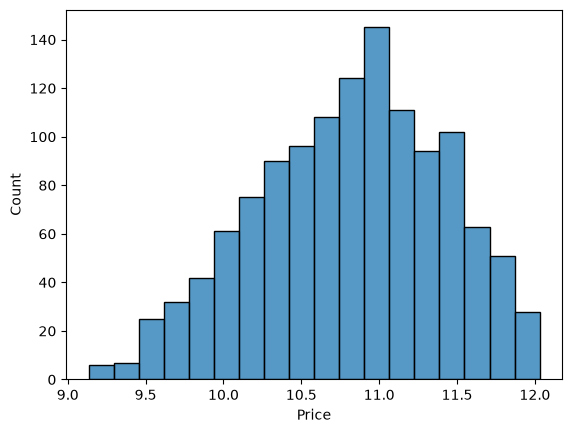

In [3]:
# Let's look at the distribution first to see what we're working with.
sns.histplot(df,x="Price")

<Axes: xlabel='target_binned', ylabel='Count'>

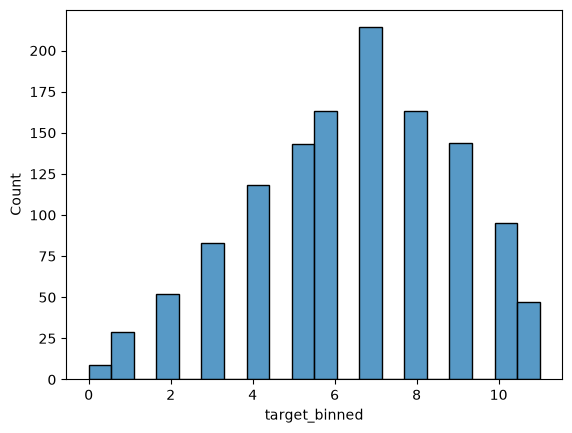

In [4]:
# Create 12 bins of price. 
target = "Price"

# create temporary categories based on our regression target => binning
df['target_binned'] = pd.cut(df[target], bins=12, labels=False)

# That looks like so.
sns.histplot(df, x="target_binned")

In [5]:
# This is really helpful to help you set the 'strategy' parameter in Undersampling.
# NOTE: This assumes your dataframe is called `df`

# Insert your column name here
column_name = "target_binned"

# Extract the unique values
column = df[column_name]
unique_values = column.unique()

# For each unique value, print the count.
for unique_value in unique_values:
    count = (column == unique_value).sum()
    print(unique_value,":", count)

# Now we know our upper limits when setting the strategy.

8 : 163
6 : 163
4 : 118
11 : 47
9 : 144
3 : 83
10 : 95
7 : 214
2 : 52
0 : 9
1 : 29
5 : 143


In [ ]:
# X, y split
X = df.drop('target_binned', axis=1)
y = df['target_binned']

# Set the strategy to tailor our needs. In this case
# Say we did some extensive research into this data


# Reduce the most frequent price bins (4 to 9) so the price distribution
# is more compact, while keeping the rare bins (0 to 3, 10, 11) as they are.
strategy = {
    0 : 9,
    1 : 29,
    2 : 52,
    3 : 83,
    4 : 100,
    5 : 100,
    6 : 120,
    7 : 150,
    8 : 130,
    9 : 120,
    10 : 95,
    11 : 47
}


# Let's create the sampler object. 
sampler = RandomUnderSampler(sampling_strategy=strategy, random_state=321)

# if you just try with the default RandomUnderSampled
# you pretty much lose most of the data
# and the distribution is a weird even distribution
# but the highest prices are emphasized
# sampler = RandomUnderSampler(random_state=321)

# Use the sampler.
X_resampled, y_resampled = sampler.fit_resample(X, y)

# Put the dataframe back together after sampling.
df_resampled_rus = pd.DataFrame(X_resampled, columns=X.columns)

# if you still need the binned target for regression
# you can use this, but you can also leave it out
df_resampled_rus['target_binned'] = y_resampled

<Axes: xlabel='target_binned', ylabel='Count'>

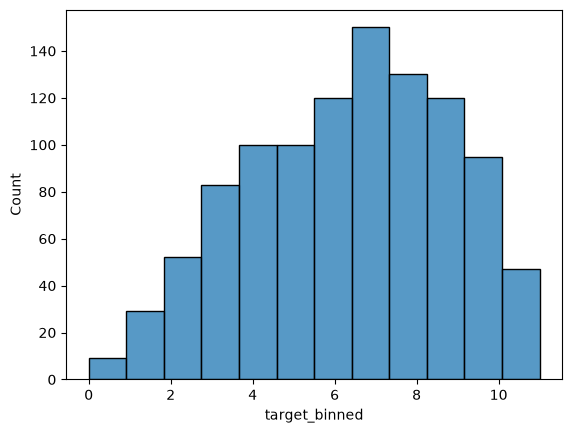

In [ ]:
# The histogram is now flatter than the original: bins 4 to 9 were reduced
# (e.g. bin 7: 214 -> 150), the rare bins (0 to 3, 10, 11) are unchanged.
sns.histplot(df_resampled_rus, x="target_binned")

In [8]:
# Check the amount of rows.
df_resampled_rus.shape

# We shaved OFF a metric ton of rows here. It's always good to keep in mind
# 1. That you're reflecting reality/population
# 2. You have enough rows to feed a ML model 

(1035, 45)

In [9]:
df

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows,target_binned
0,8,1.37,11.175755,0,1,226.983005,0,128,0,1,...,1,0,0,0,1,0,1,0,0,8
1,8,1.34,10.776777,0,0,127.677940,0,0,0,1,...,1,0,0,0,1,0,1,0,0,6
2,8,1.86,10.329931,0,0,141.211998,0,256,0,0,...,1,0,0,0,1,0,0,1,0,4
3,16,1.83,11.814476,0,1,220.534624,0,512,0,1,...,0,1,0,1,0,0,1,0,0,11
4,8,1.37,11.473101,0,1,226.983005,0,256,0,1,...,1,0,0,0,1,0,1,0,0,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1268,4,2.20,10.555257,0,0,100.454670,500,0,0,0,...,0,1,0,0,0,1,0,0,1,5
1269,4,1.80,10.433899,1,1,157.350512,0,128,0,0,...,0,1,0,0,1,0,0,0,1,5
1270,16,1.30,11.288115,1,1,276.053530,0,512,0,0,...,0,1,0,0,1,0,0,0,1,8
1271,2,1.50,9.409283,0,0,111.935204,0,0,0,0,...,0,0,1,0,1,0,0,0,1,1


In [10]:
df_resampled_rus

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows,target_binned
791,4,1.22,9.288274,0,0,157.350512,0,0,0,0,...,0,0,1,0,1,0,0,0,1,0
1214,2,1.30,9.134616,0,0,135.094211,0,32,1,0,...,0,0,1,0,1,0,0,1,0,0
1120,4,1.35,9.253676,0,0,165.632118,0,0,0,0,...,0,0,1,0,1,0,0,0,1,0
1102,4,2.20,9.317895,0,0,100.454670,0,16,1,0,...,0,0,1,0,1,0,0,1,0,0
20,2,0.98,9.232535,0,0,135.094211,0,0,0,0,...,0,0,1,0,1,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
273,16,1.36,11.799207,1,0,209.800683,0,512,0,0,...,0,1,0,0,1,0,0,0,1,11
311,16,1.21,11.799207,1,1,331.264236,0,1000,0,0,...,0,1,0,0,1,0,0,0,1,11
204,16,2.80,12.000096,0,0,282.423996,1000,256,0,0,...,0,0,1,0,0,1,0,0,1,11
693,8,1.42,11.834974,1,0,209.800683,0,256,0,0,...,0,1,0,0,1,0,0,0,1,11


In [11]:
# switching to decimal notation for the variance checks
pd.set_option('display.float_format', lambda x: "%.2f" % x)

In [ ]:
# Comparing the two statistically
# Means stay close to the original (e.g. Price 10.81 -> 10.81,
# Ram 8.25 -> 8.35), but spread increases slightly (Price std 0.60 -> 0.65,
# Ram std 4.53 -> 4.76) because the dense middle price bins were reduced.
# SSD median dropped from 256 to 180.
df.describe()

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows,target_binned
count,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,...,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00,1260.00
mean,8.25,2.03,10.81,0.15,0.28,146.48,414.81,180.59,0.08,0.02,...,0.34,0.40,0.11,0.14,0.56,0.30,0.02,0.12,0.86,6.44
std,4.53,0.65,0.60,0.35,0.45,42.35,518.49,176.34,0.27,0.13,...,0.47,0.49,0.31,0.35,0.50,0.46,0.13,0.33,0.34,2.50
min,2.00,0.69,9.13,0.00,0.00,90.58,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,4.00,1.50,10.37,0.00,0.00,127.34,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,5.00
50%,8.00,2.04,10.86,0.00,0.00,141.21,0.00,256.00,0.00,0.00,...,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00,7.00
75%,8.00,2.30,11.27,0.00,1.00,157.35,1000.00,256.00,0.00,0.00,...,1.00,1.00,0.00,0.00,1.00,1.00,0.00,0.00,1.00,8.00
max,32.00,4.60,12.03,1.00,1.00,352.47,2000.00,1024.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,11.00


In [13]:
# fairly similar results, except price due to binning probably
df_resampled_rus.describe()

,Ram,Weight,Price,TouchScreen,Ips,Ppi,HDD,SSD,Company_Acer,Company_Apple,...,Cpu_brand_Intel Core i5,Cpu_brand_Intel Core i7,Cpu_brand_Other Intel Processor,Gpu_brand_AMD,Gpu_brand_Intel,Gpu_brand_Nvidia,Os_Mac,Os_Others,Os_Windows,target_binned
count,1035.00,1035.00,1035.00,1035.00,1035.00,1035.00,1035.00,1035.00,1035.00,1035.00,...,1035.00,1035.00,1035.00,1035.00,1035.00,1035.00,1035.00,1035.00,1035.00,1035.00
mean,8.35,2.04,10.81,0.14,0.27,146.26,431.56,180.34,0.08,0.02,...,0.31,0.40,0.13,0.14,0.56,0.31,0.02,0.12,0.86,6.41
std,4.76,0.67,0.65,0.35,0.44,43.36,525.47,182.71,0.28,0.12,...,0.46,0.49,0.33,0.34,0.50,0.46,0.12,0.33,0.35,2.67
min,2.00,0.69,9.13,0.00,0.00,90.58,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,4.00,1.50,10.32,0.00,0.00,127.34,0.00,0.00,0.00,0.00,...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,1.00,4.00
50%,8.00,2.04,10.87,0.00,0.00,141.21,0.00,180.00,0.00,0.00,...,0.00,0.00,0.00,0.00,1.00,0.00,0.00,0.00,1.00,7.00
75%,8.00,2.30,11.31,0.00,1.00,157.35,1000.00,256.00,0.00,0.00,...,1.00,1.00,0.00,0.00,1.00,1.00,0.00,0.00,1.00,9.00
max,32.00,4.60,12.03,1.00,1.00,352.47,2000.00,1024.00,1.00,1.00,...,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,11.00


In [14]:
# let's see the variances too
df.var(numeric_only=True)

Ram                                   20.51
Weight                                 0.42
Price                                  0.37
TouchScreen                            0.13
Ips                                    0.20
Ppi                                 1793.57
HDD                               268834.84
SSD                                31094.59
Company_Acer                           0.07
Company_Apple                          0.02
Company_Asus                           0.10
Company_Chuwi                          0.00
Company_Dell                           0.18
Company_Fujitsu                        0.00
Company_Google                         0.00
Company_HP                             0.17
Company_Huawei                         0.00
Company_LG                             0.00
Company_Lenovo                         0.18
Company_MSI                            0.04
Company_Mediacom                       0.01
Company_Microsoft                      0.00
Company_Razer                   

In [ ]:
# Variances went up a little after undersampling (e.g. Ram 20.51 -> 22.64,
# Price 0.37 -> 0.42, Ppi 1793.57 -> 1879.94), since removing rows from the
# crowded middle bins makes the remaining data more spread out.
df_resampled_rus.var(numeric_only=True)

Ram                                   22.64
Weight                                 0.45
Price                                  0.42
TouchScreen                            0.12
Ips                                    0.20
Ppi                                 1879.94
HDD                               276120.70
SSD                                33383.36
Company_Acer                           0.08
Company_Apple                          0.02
Company_Asus                           0.11
Company_Chuwi                          0.00
Company_Dell                           0.18
Company_Fujitsu                        0.00
Company_Google                         0.00
Company_HP                             0.16
Company_Huawei                         0.00
Company_LG                             0.00
Company_Lenovo                         0.18
Company_MSI                            0.04
Company_Mediacom                       0.01
Company_Microsoft                      0.00
Company_Razer                   